In [15]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import tqdm
import tiktoken

|구분|구성 1 (안정 균형형)|구성 2 (고성능 정밀형)
|--|--|--|
Vector DB|Qdrant|Qdrant
Dense Vector|OpenAI text-embedding-3-small|OpenAI text-embedding-3-small|
Sparse Vector | BM25 Retriever (전통적인 키워드 기반 스파스 검색으로 빠르고 안정적이며 구현이 단순함) | SPLADE Retriever **(딥러닝 기반 스파스 확장으로 의미 유사도를 반영해 BM25보다 정밀한 검색이 가능함)**
Re-Ranking|BAAI/bge-reranker-v2-m3(경량화된 리랭커 모델)|BAAI/bge-reranker-v2-gemma **(영어 성능과 전반적인 다국어 처리 능력 모두에서 우수한 성능을 보임)**
최종 답변 (LLM)|GPT-5|GPT-5




In [5]:
df = pd.read_csv("rfp_docs.csv")
print(len(df))
print(df.columns)
df.head()

98
Index(['project_id', '공고 번호', 'title', 'full_text', 'char_len'], dtype='object')


,project_id,공고 번호,title,full_text,char_len
0,proj_001,20241001798,한영대학교 특성화 맞춤형 교육환경 구축 - 트랙운영 학사정보시스템 고도화,\n\n# [FILE: 20241001798-00_1728004387170_입찰공고...,74335
1,proj_002,20241002912,2024년 대학산학협력활동 실태조사 시스템(UICC) 기능개선,\n\n# [FILE: 20241002912-00_1728021605690_입찰공고...,113858
2,proj_003,20240827859,EIP3.0 고압가스 안전관리 시스템 구축 용역,\n\n# [FILE: 20240827859-00_1724812213958_입찰공고...,149328
3,proj_004,20240430918,도시계획위원회 통합관리시스템 구축용역,\n\n# [FILE: 20240430918-00_1713425115125_입찰공고...,161541
4,proj_005,20240430896,봉화군 재난통합관리시스템 고도화 사업(협상)(긴급),\n\n# [FILE: 20240430896-00_1713425345417_과업지시...,150413


In [6]:
print("char_len 확인\n")
print(df['char_len'].describe())

char_len 확인

count        98.000000
mean     125942.030612
std       53769.478683
min       58717.000000
25%       91501.750000
50%      111611.000000
75%      146204.500000
max      361068.000000
Name: char_len, dtype: float64


- 실제 gpt-5 토큰도 숫자가 다름
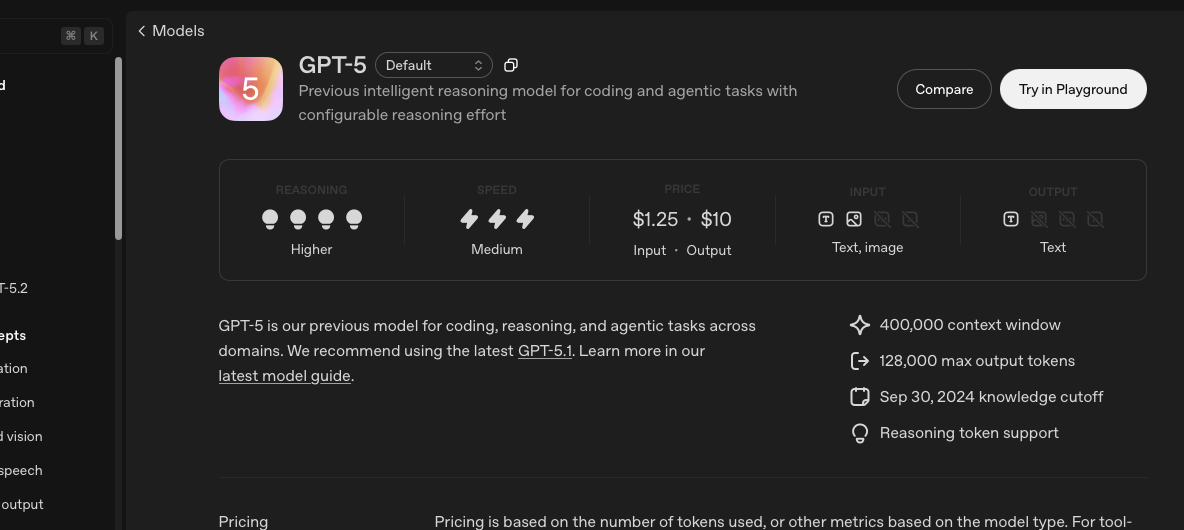

In [7]:
# CHECKLIST: 이승완 max token 차이

# https://platform.openai.com/docs/models/gpt-5
# 전체 토큰 제한
# model_limits = {
#     "GPT-5 Nano": 32_000,
#     "GPT-5 Mini": 128_000,
#     "GPT-5": 200_000
# }  

# 문서별 토큰 개수 세기

In [8]:
tokenizer = tiktoken.get_encoding("cl100k_base")
df['token_count'] = df['full_text'].apply(
    lambda x: len(tokenizer.encode(str(x)))
)
token_stats = {
    "min(0%)": df['token_count'].min(),
    "25%": df['token_count'].quantile(0.25),
    "50%(median)": df['token_count'].quantile(0.50),
    "75%": df['token_count'].quantile(0.75),
    "max(100%)": df['token_count'].max(),
    "mean": df['token_count'].mean(),
    "std":df['token_count'].std()
}

for k, v in token_stats.items():
    print(f"{k:<12}: {int(v):,} tokens")

# CHECKLIST: 이승완 가장 큰 문서를 기준으로 자른다가 아닌 거 같음. + 한번에 임베딩 시키는게 아니지않나

min(0%)     : 52,430 tokens
25%         : 80,198 tokens
50%(median) : 97,927 tokens
75%         : 127,544 tokens
max(100%)   : 334,756 tokens
mean        : 111,187 tokens
std         : 48,824 tokens


- std가 약 5만토큰 -> , 나머지도 당연히 chunking.


데이터 로드 중
98개 문서 해부 시작

[분석 진단 결과]
1. 세부 목차(H2/H3) 실종: 98개 문서 (100.0%)
   -> 이 문서들은 '# 1. 제목' 안에 내용이 통째로 들어있을 확률이 높음
2. 거대 섹션(2000자 초과) 보유: 98개 문서 (100.0%)
   -> 이 문서들은 마크다운 청킹만 하면 '검색 불가' 영역이 발생
3. 가장 긴 섹션(Worst Case): 단일 챕터가 120,537자 (약 60,268 토큰)
   -> Recursive 청킹 없이는 절대 처리가 불가능한 크기


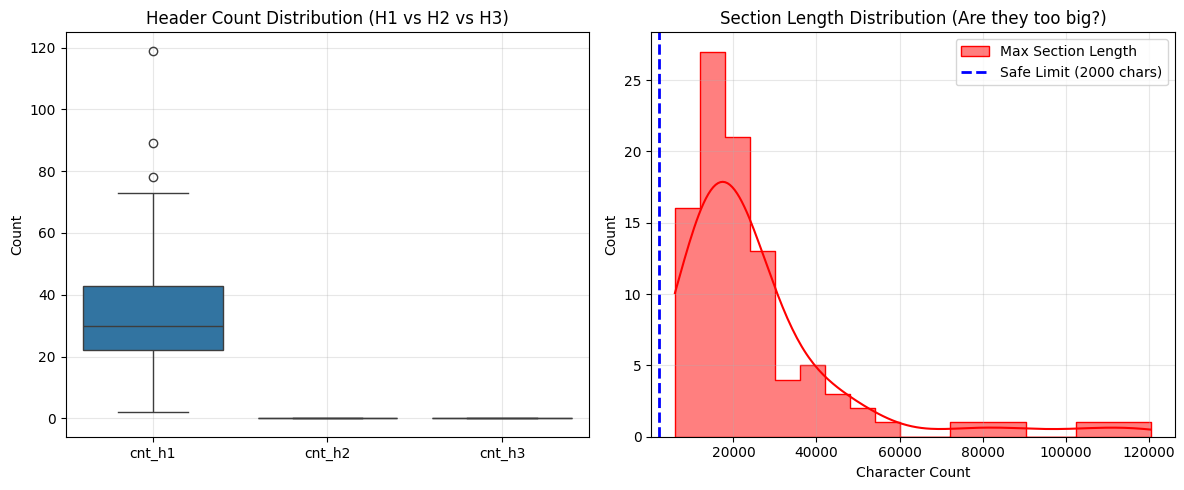

In [9]:

docs_path = "rfp_docs.csv"

if not os.path.exists(docs_path):
    print("파일이 없음")
    exit()

print("데이터 로드 중")
df = pd.read_csv(docs_path)

# ==========================================
# [분석 함수] 뼈대 해부
# ==========================================
def analyze_skeleton(row):
    text = str(row['full_text'])

    # 1. 계층별 헤더 개수 카운트
    # (반드시 줄바꿈 후 #이 오는 패턴만 인정)
    h1 = text.count("\n# ")
    h2 = text.count("\n## ")
    h3 = text.count("\n### ")
    total_headers = h1 + h2 + h3

    # 2. 헤더 간 거리(Section Length) 측정
    # 정규식으로 헤더(#, ##, ###)를 기준으로 텍스트를 찢어본다
    # 이 조각(Section)들의 길이가 곧 우리가 처리해야 할 덩어리 크기
    sections = re.split(r'\n#{1,3} ', text)

    # 공백 제거 후 길이 측정
    section_lens = [len(s.strip()) for s in sections if len(s.strip()) > 0]

    if not section_lens:
        max_sec = 0
        mean_sec = 0
        median_sec = 0
    else:
        max_sec = max(section_lens)      # 가장 긴 챕터의 길이 (최악의 경우)
        mean_sec = np.mean(section_lens) # 평균 챕터 길이
        median_sec = np.median(section_lens)

    return pd.Series([h1, h2, h3, total_headers, max_sec, mean_sec, median_sec])

# ==========================================
# [실행]
# ==========================================
print(f"{len(df)}개 문서 해부 시작")
cols = ['cnt_h1', 'cnt_h2', 'cnt_h3', 'total_headers', 'max_sec_len', 'mean_sec_len', 'median_sec_len']
df[cols] = df.apply(analyze_skeleton, axis=1)

# ==========================================
# [진단 결과 리포트]
# ==========================================
print("\n" + "="*60)
print("[분석 진단 결과]")
print("="*60)

# 1. 헤더 실종 문서 (H2, H3가 없는 경우)
no_subheaders = len(df[df['cnt_h2'] + df['cnt_h3'] == 0])
print(f"1. 세부 목차(H2/H3) 실종: {no_subheaders}개 문서 ({no_subheaders/len(df)*100:.1f}%)")
print(f"   -> 이 문서들은 '# 1. 제목' 안에 내용이 통째로 들어있을 확률이 높음")

# 2. 거대 섹션 존재 여부 (가장 중요한 지표)
# 2000자(약 1000토큰)를 넘어가면 검색 정확도가 떨어지기 시작함
huge_sections = len(df[df['max_sec_len'] > 2000])
print(f"2. 거대 섹션(2000자 초과) 보유: {huge_sections}개 문서 ({huge_sections/len(df)*100:.1f}%)")
print(f"   -> 이 문서들은 마크다운 청킹만 하면 '검색 불가' 영역이 발생")

# 3. 최악의 경우 (가장 긴 섹션 길이)
worst_max_len = df['max_sec_len'].max()
print(f"3. 가장 긴 섹션(Worst Case): 단일 챕터가 {worst_max_len:,.0f}자 (약 {worst_max_len//2:,.0f} 토큰)")
print("   -> Recursive 청킹 없이는 절대 처리가 불가능한 크기")

# ==========================================
# [시각화]
# ==========================================
plt.figure(figsize=(12, 5))

# 그래프 1: 헤더 개수 분포
plt.subplot(1, 2, 1)
sns.boxplot(data=df[['cnt_h1', 'cnt_h2', 'cnt_h3']])
plt.title("Header Count Distribution (H1 vs H2 vs H3)")
plt.ylabel("Count")
plt.grid(True, alpha=0.3)

# 그래프 2: 섹션 길이 분포 (Max vs Mean)
plt.subplot(1, 2, 2)
# 로그 스케일 적용 (값이 너무 커서 그래프가 찌그러지는 것 방지)
sns.histplot(df['max_sec_len'], color='red', label='Max Section Length', kde=True, element="step")
plt.axvline(2000, color='blue', linestyle='--', linewidth=2, label='Safe Limit (2000 chars)')
plt.title("Section Length Distribution (Are they too big?)")
plt.xlabel("Character Count")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

- 실제로 최악의 케이스인 한 목차(#)안에 12만자가 있는 경우는 proj_092라고 나오는데 ('\n #) 이런 경우입니다.
- sections = re.split(r'\n#{1,3} ', text) regular expression에서 '\s*' 를 추가하지 않아서 너무 엄격함.
'

In [10]:
import pandas as pd
import re
import os

# 파일 경로 설정 (사용자 환경에 맞게 수정 필요)
docs_path = "rfp_docs.csv"

if os.path.exists(docs_path):
    df = pd.read_csv(docs_path)
    
    def get_max_section_length(text):
        # 1. 헤더(#, ##, ###)를 기준으로 텍스트를 쪼갭니다.
        sections = re.split(r'\n#{1,3} ', str(text))
        
        # 2. 가장 긴 섹션의 길이를 찾습니다.
        if not sections:
            return 0
        return max(len(s.strip()) for s in sections)

    # 3. 각 문서별 최대 섹션 길이 계산
    df['max_section_len'] = df['full_text'].apply(get_max_section_length)
    
    # 4. 가장 긴 섹션을 가진 프로젝트 찾기
    worst_case_row = df.loc[df['max_section_len'].idxmax()]
    
    print("="*50)
    print("[최악의 케이스 발견]")
    print("="*50)
    print(f"프로젝트 ID {worst_case_row.get('project_id', 'N/A')}")
    print(f"프로젝트 제목: {worst_case_row.get('title', '제목 없음')}")
    print(f"가장 긴 섹션 길이: {worst_case_row['max_section_len']:,}자")
    print("-" * 50)
    
else:
    print(f"파일을 찾을 수 없습니다: {docs_path}")


[최악의 케이스 발견]
프로젝트 ID proj_092
프로젝트 제목: 2024년도 GKL  그룹웨어 시스템 구축 용역
가장 긴 섹션 길이: 120,537자
--------------------------------------------------


In [11]:
import pandas as pd
import re
import os
import tiktoken

# 파일 경로 설정
docs_path = "rfp_docs.csv"

if os.path.exists(docs_path):
    df = pd.read_csv(docs_path)
    
    # 토크나이저 준비
    tokenizer = tiktoken.get_encoding("cl100k_base")
    
    # 91번 문서 (12만 자짜리)
    target_idx = 91
    
    if target_idx in df.index:
        text = str(df.loc[target_idx, 'full_text'])
        
        print(f"[{target_idx}번 문서 분석 시작]")
        print(f"총 길이: {len(text):,}자")
        
        # 엄격한 기준 정규식: 줄바꿈 + 샵(1~3개) + 공백
        pattern = re.compile(r'\n#{1,3} ')
        matches = list(pattern.finditer(text))
        
        max_len = 0
        max_start = 0
        max_end = 0
        
        # (1) 문서 시작 ~ 첫 헤더
        if matches:
            first_chunk_len = matches[0].start()
            if first_chunk_len > max_len:
                max_len = first_chunk_len
                max_start = 0
                max_end = matches[0].start()
            
            # (2) 헤더 ~ 헤더 사이
            for i in range(len(matches) - 1):
                current_start = matches[i].end()
                next_start = matches[i+1].start()
                chunk_len = next_start - current_start
                
                if chunk_len > max_len:
                    max_len = chunk_len
                    max_start = current_start
                    max_end = next_start
            
            # (3) 마지막 헤더 ~ 문서 끝
            last_start = matches[-1].end()
            last_len = len(text) - last_start
            if last_len > max_len:
                max_len = last_len
                max_start = last_start
                max_end = len(text)
                
        else:
            max_len = len(text)
            max_start = 0
            max_end = len(text)

        # 토큰 수 계산
        longest_section_text = text[max_start:max_end]
        token_count = len(tokenizer.encode(longest_section_text))

        print(f"가장 긴 섹션 길이: {max_len:,}자")
        print(f"가장 긴 섹션 토큰 수: {token_count:,} Tokens")
        print("-" * 40)
        
        if token_count > 8191:
            print("🚨 [경고] 임베딩 모델 한도(8,191)를 초과했습니다!")
        
        # 앞뒤 문맥 추출
        start_snippet = text[max_start:max_start+30].replace('\n', '\\n')
        end_snippet = text[max_end-50:max_end].replace('\n', '\\n')
        
        print("\n[가장 긴 섹션의 정체]")
        print(f"시작 부분: \"{start_snippet}...\"")
        print(f"끝 부분: \"...{end_snippet}\"")

    else:
        print(f"{target_idx}번 문서가 존재하지 않습니다.")
else:
    print(f"파일을 찾을 수 없습니다: {docs_path}")


[91번 문서 분석 시작]
총 길이: 207,152자
가장 긴 섹션 길이: 120,538자
가장 긴 섹션 토큰 수: 104,166 Tokens
----------------------------------------
🚨 [경고] 임베딩 모델 한도(8,191)를 초과했습니다!

[가장 긴 섹션의 정체]
시작 부분: "4. 상세 요구사항 # 1) 시스템 장비 구성 요구사항..."
끝 부분: "... | 산출정보 |  |\n| 관련 요구사항 | 관련 요구사항 | N/A |\n - 121 -\n"


- 여기에서 tiktoken으로 측정한 토큰 수 하지 않고 //2 로 단순하게 나눠서 토큰 계산함
```
worst_max_len = df['max_sec_len'].max()
print(f"3. 가장 긴 섹션(Worst Case): 단일 챕터가 {worst_max_len:,.0f}자 (약 {worst_max_len//2:,.0f} 토큰)")
print("   -> Recursive 청킹 없이는 절대 처리가 불가능한 크기")
```
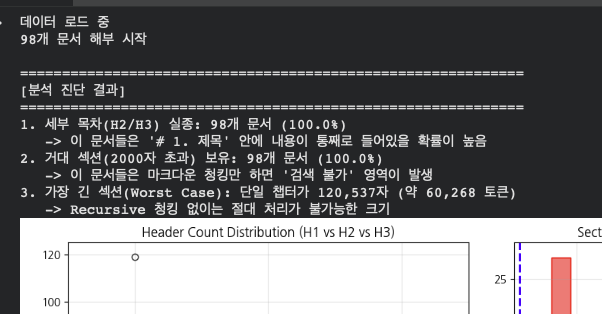
========================
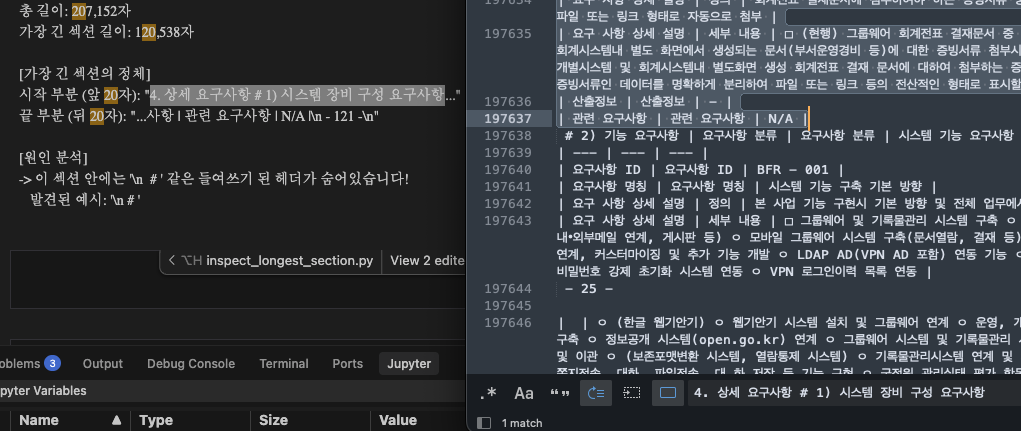
==========================
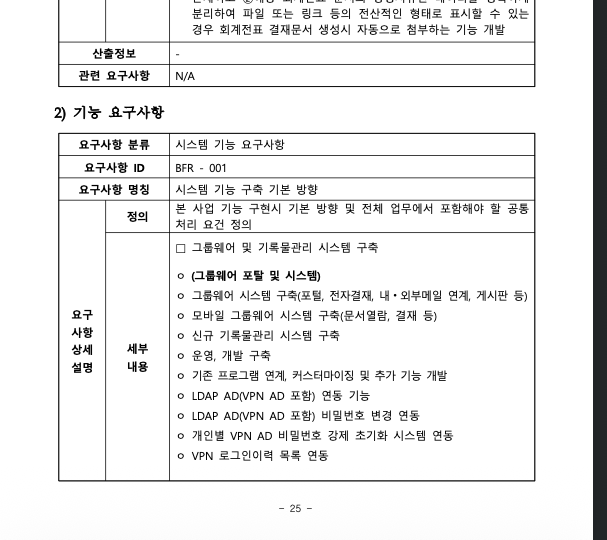

In [22]:
import pandas as pd
import re
import os
import tiktoken

# 파일 경로 설정
docs_path = "rag_chunks_recursive-2.csv"

if os.path.exists(docs_path):
    df = pd.read_csv(docs_path)
    
    # 토크나이저 준비 (GPT-4/5용)
    tokenizer = tiktoken.get_encoding("cl100k_base")
    
    # 1. 느슨한 기준(들여쓰기 허용)으로 가장 긴 섹션을 가진 문서 찾기
    def get_max_section_length_loose(text):
        sections = re.split(r'\n\s*#{1,3}\s+', str(text))
        if not sections: return 0
        return max(len(s.strip()) for s in sections)

    df['max_section_len_loose'] = df['full_text'].apply(get_max_section_length_loose)
    worst_idx = df['max_section_len_loose'].idxmax()
    worst_len = df.loc[worst_idx, 'max_section_len_loose']
    
    print(f"분석 대상 문서: {worst_idx}번 (길이: {len(str(df.loc[worst_idx, 'full_text'])):,}자)")
    print(f"가장 긴 섹션 길이: {worst_len:,}자")
    
    text = str(df.loc[worst_idx, 'full_text'])
    
    # 2. 해당 문서에서 가장 긴 섹션의 위치 정밀 추적
    pattern = re.compile(r'\n\s*#{1,3}\s+')
    matches = list(pattern.finditer(text))
    
    max_chunk_len = 0
    start_idx = 0
    end_idx = 0
    
    # (1) 문서 시작 ~ 첫 헤더
    if matches:
        first_chunk_len = matches[0].start()
        if first_chunk_len > max_chunk_len:
            max_chunk_len = first_chunk_len
            start_idx = 0
            end_idx = matches[0].start()
            
        # (2) 헤더 ~ 헤더 사이
        for i in range(len(matches) - 1):
            current_end = matches[i].end()
            next_start = matches[i+1].start()
            chunk_len = next_start - current_end
            
            if chunk_len > max_chunk_len:
                max_chunk_len = chunk_len
                start_idx = current_end
                end_idx = next_start
                
        # (3) 마지막 헤더 ~ 문서 끝
        last_end = matches[-1].end()
        last_chunk_len = len(text) - last_end
        if last_chunk_len > max_chunk_len:
            max_chunk_len = last_chunk_len
            start_idx = last_end
            end_idx = len(text)
            
    else:
        start_idx = 0
        end_idx = len(text)

    # 3. 토큰 수 계산 (가장 긴 섹션의 실제 내용만)
    longest_section_text = text[start_idx:end_idx]
    token_count = len(tokenizer.encode(longest_section_text))
    
    print(f"가장 긴 섹션 토큰 수: {token_count:,} Tokens")
    print("-" * 40)
    
    # 경고 메시지
    if token_count > 8191:
        print("🚨 [경고] 임베딩 모델 한도(8,191)를 초과했습니다!")
        print("   -> 이 섹션은 뒷부분이 잘려서 검색되지 않습니다.")
    else:
        print("✅ [안전] 임베딩 모델 한도 이내입니다.")

    # 4. 앞뒤 50자 추출
    print("\n" + "="*60)
    print("[가장 긴 섹션의 앞/뒤 문맥 확인]")
    print("="*60)
    
    context_start = max(0, start_idx - 50)
    prefix = text[context_start:start_idx].replace('\n', '\\n')
    content_start = text[start_idx:start_idx+50].replace('\n', '\\n')
    
    print(f"1. 시작 지점 (헤더 + 내용 시작 50자)")
    print(f"   [헤더 추정]: ...{prefix}")
    print(f"   [내용 시작]: {content_start}...")
    
    context_end = min(len(text), end_idx + 50)
    content_end = text[end_idx-50:end_idx].replace('\n', '\\n')
    suffix = text[end_idx:context_end].replace('\n', '\\n')
    
    print(f"\n2. 끝 지점 (내용 끝 50자 + 다음 헤더)")
    print(f"   [내용 끝]: ...{content_end}")
    print(f"   [다음 헤더]: {suffix}...")

else:
    print("파일이 없습니다.")


KeyError: 'full_text'

## 실제로 proj_008 봐서 봤고 5만2천자 사이에 느슨한 목차가 없었음
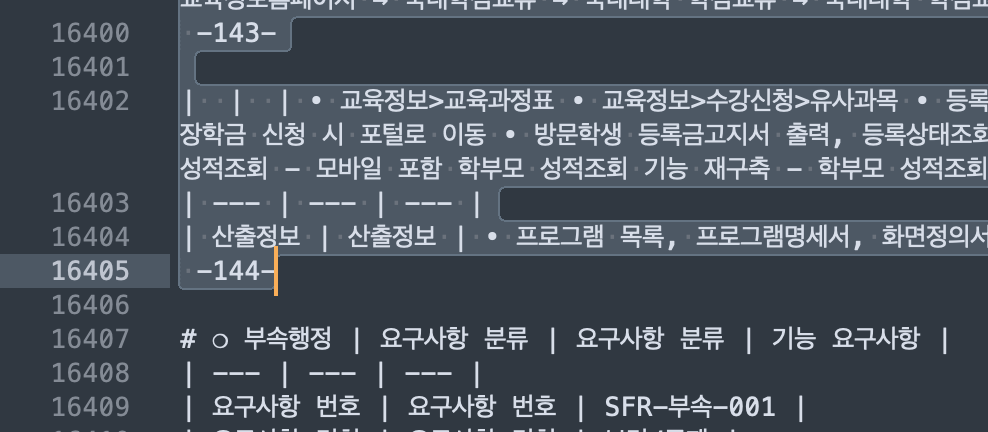

표 길이 계산 중...

[거대 표(Giant Table) 정밀 진단]
1. 1,000자 초과 표 보유 문서: 98개 (100.0%)
2. 2,000자 초과 표 보유 문서: 94개 (95.9%)
3. 평균 표 길이 (표 있는 문서 기준): 4,370자
4. 가장 긴 표 길이 (최악의 경우): 14,270자

[경고] 2,000자를 넘는 표가 존재합니다.


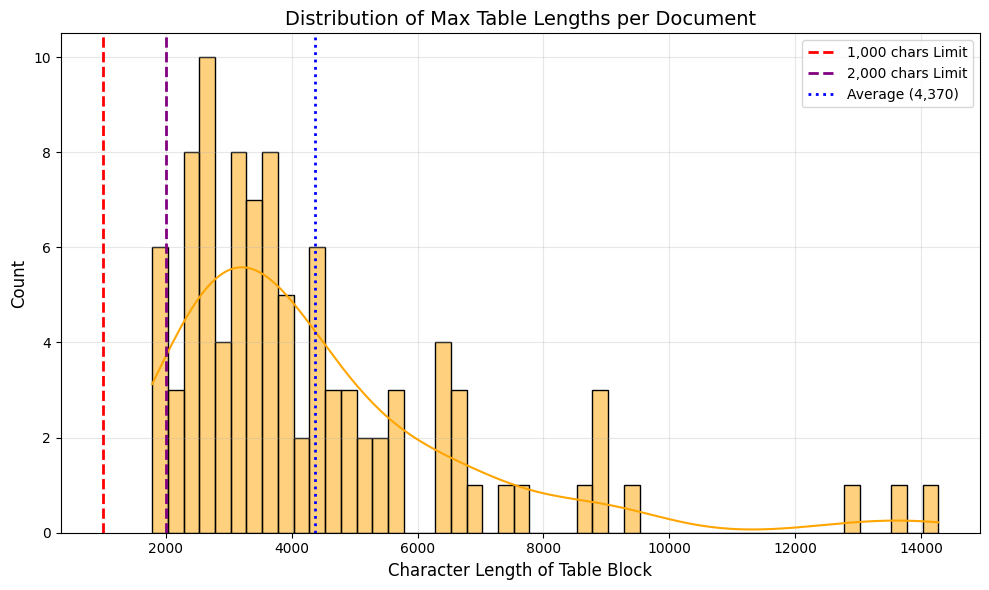

In [13]:
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 파일 경로 설정
docs_path = "rfp_docs.csv"

if os.path.exists(docs_path):
    df = pd.read_csv(docs_path)
    
    # 1. 표(Table) 길이 계산 함수 정의
    def get_max_table_len(text):
        text = str(text)
        lines = text.split('\n') # \n 기준으로 한줄한줄 읽고
        max_len = 0
        current_table_len = 0
        in_table = False
        
        for line in lines:
            # 파이프(|)가 있고 하이픈(-)이나 내용이 있는 경우 표로 간주
            # (단순히 |만 있는 경우 제외하기 위해 최소한의 조건 추가)
            if '|' in line:
                current_table_len += len(line) + 1 # 줄바꿈 문자 포함
                in_table = True
            else:
                if in_table:
                    max_len = max(max_len, current_table_len)
                    current_table_len = 0
                    in_table = False
        
        # 마지막에 표로 끝난 경우 처리
        if in_table:
            max_len = max(max_len, current_table_len)
            
        return max_len

    # 2. 계산 실행
    print("표 길이 계산 중...")
    df['max_table_char_len'] = df['full_text'].apply(get_max_table_len)
    
    # 3. 통계 산출
    total_docs = len(df)
    tables_over_1000 = len(df[df['max_table_char_len'] > 1000])
    tables_over_2000 = len(df[df['max_table_char_len'] > 2000])
    avg_table_len = df[df['max_table_char_len'] > 0]['max_table_char_len'].mean() # 표가 있는 문서만 대상으로 평균
    max_table_len = df['max_table_char_len'].max()
    
    print("\n" + "="*60)
    print("[거대 표(Giant Table) 정밀 진단]")
    print("="*60)
    print(f"1. 1,000자 초과 표 보유 문서: {tables_over_1000}개 ({tables_over_1000/total_docs*100:.1f}%)")
    print(f"2. 2,000자 초과 표 보유 문서: {tables_over_2000}개 ({tables_over_2000/total_docs*100:.1f}%)")
    print(f"3. 평균 표 길이 (표 있는 문서 기준): {avg_table_len:,.0f}자")
    print(f"4. 가장 긴 표 길이 (최악의 경우): {max_table_len:,.0f}자")
    
    if tables_over_2000 > 0:
        print("\n[경고] 2,000자를 넘는 표가 존재합니다.")

    # 4. 시각화
    plt.figure(figsize=(10, 6))
    
    # 히스토그램 (표가 있는 문서만)
    table_data = df[df['max_table_char_len'] > 0]['max_table_char_len']
    
    sns.histplot(table_data, bins=50, color='orange', kde=True)
    
    # 기준선 추가
    plt.axvline(1000, color='red', linestyle='--', linewidth=2, label='1,000 chars Limit')
    plt.axvline(2000, color='purple', linestyle='--', linewidth=2, label='2,000 chars Limit')
    plt.axvline(avg_table_len, color='blue', linestyle=':', linewidth=2, label=f'Average ({avg_table_len:,.0f})')
    
    plt.title('Distribution of Max Table Lengths per Document', fontsize=14)
    plt.xlabel('Character Length of Table Block', fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

else:
    print(f"파일을 찾을 수 없습니다: {docs_path}")


데이터 해부 시작 (총 문서 98개)
텍스트 정밀 스캔 중


100%|██████████| 98/98 [00:00<00:00, 99.33it/s] 



[RFP 데이터 상세 통계 로그]

1. 반복 노이즈 문장 Top 10
--------------------------------------------------
1. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 69.71회/문서: | --- | --- | --- |...
2. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 21.44회/문서: | --- | --- |...
3. [노이즈: 표 템플릿] 커버리지 100.0% | 평균 10.81회/문서: | --- | --- | --- | --- |...
4. [노이즈: 표 템플릿] 커버리지 98.0% | 평균 10.64회/문서: | --- | --- | --- | --- | --- |...
5. [주의] 커버리지 35.7% | 평균 7.93회/문서: | 산출정보 | 산출정보 |  |...
6. [주의] 커버리지 53.1% | 평균 7.53회/문서: | 요구사항 분류 | 요구사항 분류 | 기능 요구사항 |...
7. [주의] 커버리지 20.4% | 평균 7.38회/문서: | 관련요구사항 | 관련요구사항 |  |...
8. [노이즈: 표 템플릿] 커버리지 96.9% | 평균 7.16회/문서: | --- | --- | --- | --- | --- | --- |...
9. [주의] 커버리지 19.4% | 평균 5.20회/문서: | 관련 요구사항 | 관련 요구사항 |  |...
10. [노이즈: 표 템플릿] 커버리지 91.8% | 평균 4.56회/문서: | --- | --- | --- | --- | --- | --- | --- |...

2. 정보 패턴 발견 현황 (총 98개 문서 합계)
--------------------------------------------------
   - 금액(Price): 총 1,006 건 (문서당 평균 10.3 건)
   - 날짜(Date): 총 3,631 건 (문서당 평균 37.1 건)
   - 법률(Law): 총 3,373 건 (문서당 평균 34.4 건)
   - 

/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_15295/2872798702.py:142: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax3.boxplot(data_to_plot, labels=doc_pattern_counts.keys())
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_15295/2872798702.py:154: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_15295/2872798702.py:154: UserWarning: Glyph 48373 (\N{HANGUL SYLLABLE BOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_15295/2872798702.py:154: UserWarning: Glyph 54943 (\N{HANGUL SYLLABLE HOES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/53/bz6j7ttj061dc4fqzd1ygd_m0000gn/T/ipykernel_15295/2872798702.py:154: UserWarning: Glyph 49688 (\N{H

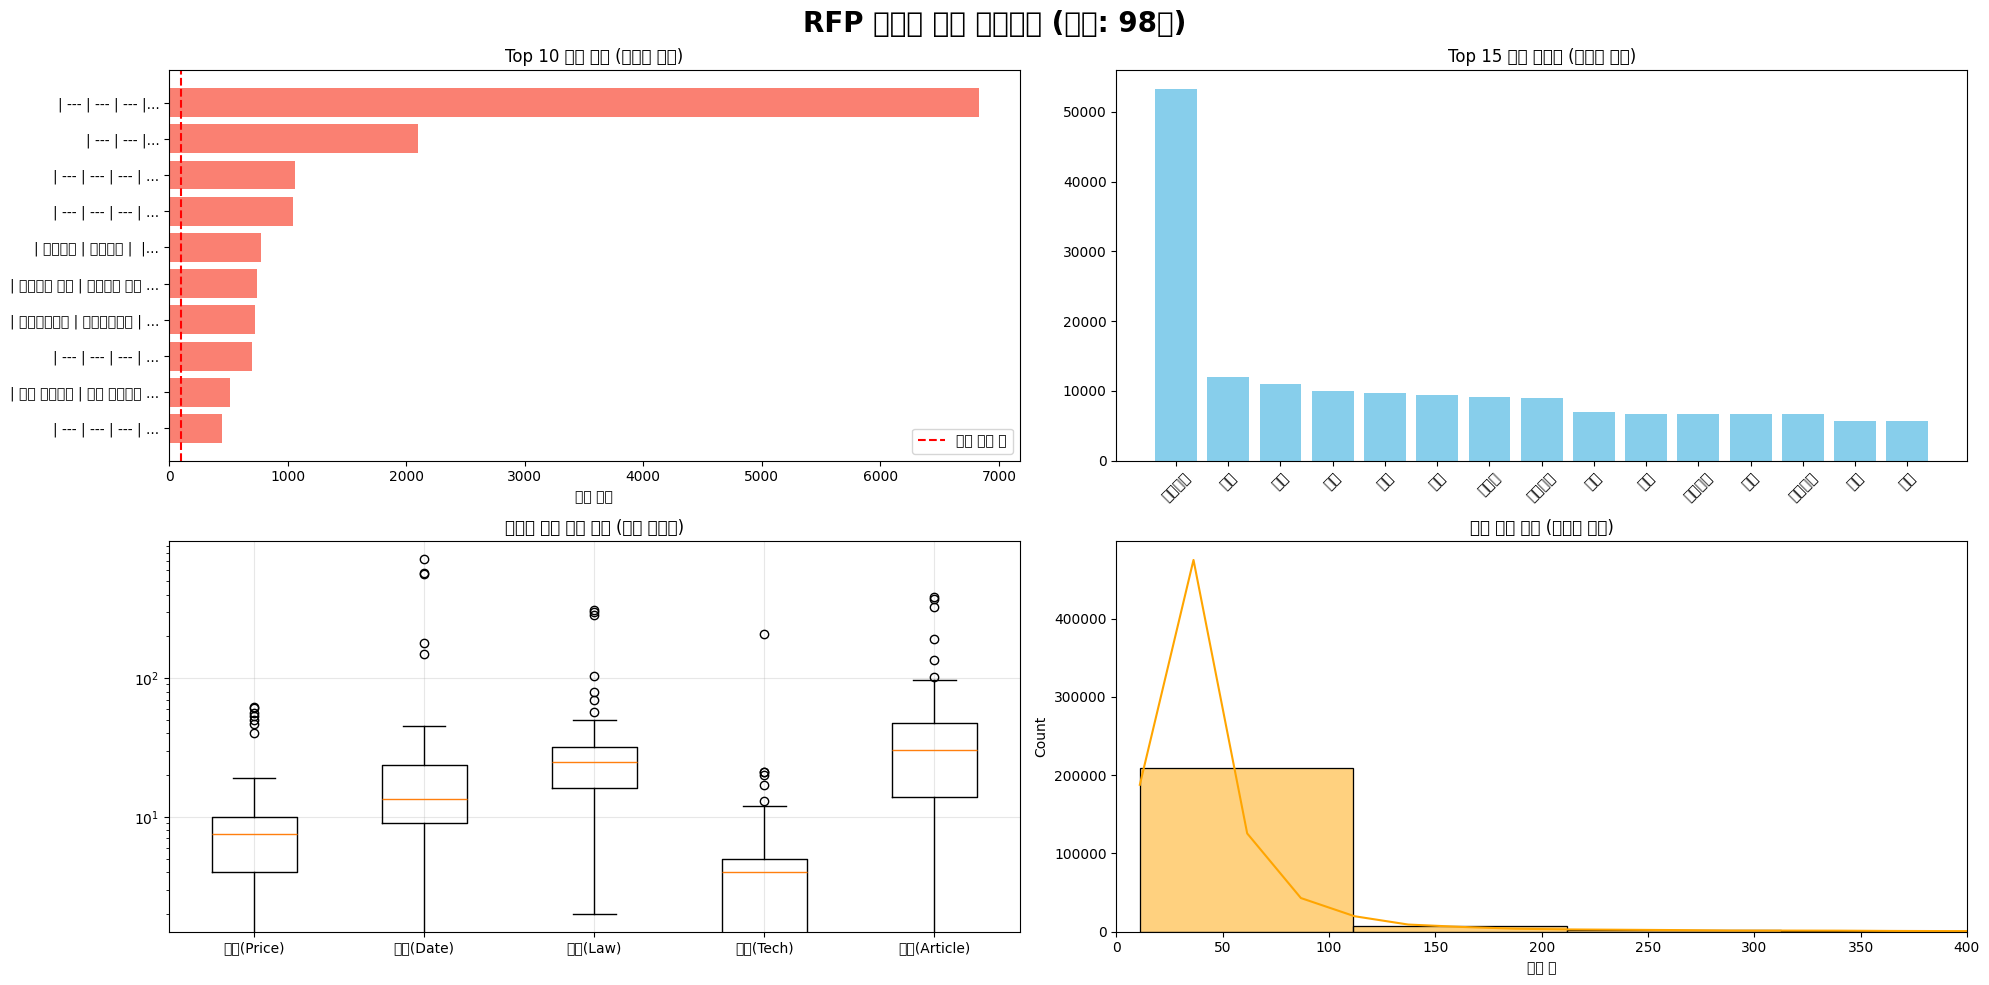

분석 완료


In [21]:


if not os.path.exists(docs_path):
    print("[에러] 파일 없음")
    exit()

df = pd.read_csv(docs_path)
print(f"데이터 해부 시작 (총 문서 {len(df)}개)")
print("="*60)

# ==========================================
# [분석] 패턴 정의 및 스캔
# ==========================================
patterns = {
    '금액(Price)': r'\d{1,3}(?:,\d{3})*\s*(?:만원|억원|원|USD)',
    '날짜(Date)': r'\d{4}[년.-]\s*\d{1,2}[월.-]\s*\d{1,2}일?',
    '법률(Law)': r'(?:법|령|규칙)\s*제\s*\d+\s*조',
    '기술(Tech)': r'[A-Za-z0-9]+(?:Server|DB|API|Cloud|Web|App|Linux|Windows)',
    '조항(Article)': r'제\s*\d+\s*조\s*[\(\[]'
}

all_sentences = []
all_words = []
pattern_counts = {k: 0 for k in patterns.keys()}
doc_pattern_counts = {k: [] for k in patterns.keys()} # 문서별 분포 확인용
sentence_lens = []

print("텍스트 정밀 스캔 중")

for text in tqdm(df['full_text']):
    text = str(text)

    # 1. 문장 분석
    sents = [s.strip() for s in re.split(r'\n|\.', text) if len(s.strip()) > 10]
    all_sentences.extend(sents)
    sentence_lens.extend([len(s) for s in sents])

    # 2. 단어 분석
    words = re.findall(r'[가-힣]{2,}', text)
    all_words.extend(words)

    # 3. 패턴 분석
    for p_name, p_regex in patterns.items():
        found = len(re.findall(p_regex, text, re.IGNORECASE))
        pattern_counts[p_name] += found
        doc_pattern_counts[p_name].append(found)

# ==========================================
# [로그 출력] 상세 통계 리포트
# ==========================================
print("\n" + "="*60)
print("[RFP 데이터 상세 통계 로그]")
print("="*60)

# # 1. 반복 문장 (노이즈)
# print(f"\n1. 반복 노이즈 문장 Top 10 (문서당 평균 반복 횟수 기준)")
# print("-" * 50)

# top_sents = Counter(all_sentences).most_common(10)
# for i, (sent, total_count) in enumerate(top_sents, 1):
#     # 문서당 평균 반복 횟수 계산
#     avg_per_doc = total_count / len(df)
#     # 평균 반복 횟수가 매우 높은 문장을 노이즈로 판단
#     tag = "[노이즈: 표 템플릿]" if avg_per_doc > 10 else "[주의]"
#     print(f"{i}. {tag} 문서당 평균 {avg_per_doc:.1f}회): {sent[:50]}...")

# 1. 반복 문장 (노이즈)
print(f"\n1. 반복 노이즈 문장 Top 10")
print("-" * 50)

# 문장별 총 등장 횟수와 문서 커버리지 계산
sentence_total_counts = Counter(all_sentences)
sentence_docs = defaultdict(set)

for doc_idx, text in enumerate(df['full_text']):
    sents = [s.strip() for s in re.split(r'\n|\.', str(text)) if len(s.strip()) > 10]
    for s in set(sents):  # 중복 제거 후 문서별 등장 여부 기록
        sentence_docs[s].add(doc_idx)

top_sents = sentence_total_counts.most_common(10)

for i, (sent, total_count) in enumerate(top_sents, 1):
    doc_coverage = len(sentence_docs[sent])  # 등장 문서 수
    coverage_pct = (doc_coverage / len(df)) * 100
    avg_per_doc = total_count / len(df)      # 회/문서
    tag = "[노이즈: 표 템플릿]" if coverage_pct > 70 and avg_per_doc > 1.0 else "[주의]"
    print(f"{i}. {tag} 커버리지 {coverage_pct:.1f}% | 평균 {avg_per_doc:.2f}회/문서: {sent[:50]}...")

# 2. 정보 밀도
print(f"\n2. 정보 패턴 발견 현황 (총 {len(df)}개 문서 합계)")
print("-" * 50)
for p_name, count in pattern_counts.items():
    avg = count / len(df)
    print(f"   - {p_name}: 총 {count:,} 건 (문서당 평균 {avg:.1f} 건)")

# 3. 어휘 분포
print(f"\n3. 핵심 키워드 Top 15 (불용어 제외)")
print("-" * 50)
stopwords = ['사업', '구축', '제안', '시스템', '관련', '대한', '따라', '있는', '경우', '위하', '및', '등', '요구', '사항', '관리', '내용', '자료', '제출']
filtered_words = [w for w in all_words if w not in stopwords]
top_words = Counter(filtered_words).most_common(15)
for i, (word, count) in enumerate(top_words, 1):
    print(f"   {i}. {word} ({count:,}회)")

# 4. 문장 호흡
print(f"\n4. 문장 길이 통계")
print("-" * 50)
print(f"   - 평균 길이: {np.mean(sentence_lens):.1f} 자")
print(f"   - 최대 길이: {np.max(sentence_lens):,} 자")
print(f"   - 중간값: {np.median(sentence_lens):.1f} 자")

# ==========================================
# [시각화]
# ==========================================
print("\n그래프 생성 중")

fig = plt.figure(figsize=(20, 10))
plt.suptitle(f"RFP 데이터 해부 대시보드 (문서: {len(df)}개)", fontsize=20, weight='bold')

# 그래프 1: 반복 문장
ax1 = fig.add_subplot(2, 2, 1)
y_pos = np.arange(len(top_sents))
s_counts = [x[1] for x in top_sents]
s_labels = [x[0][:20] + "..." for x in top_sents]
ax1.barh(y_pos, s_counts, align='center', color='salmon')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(s_labels)
ax1.invert_yaxis()
ax1.set_title('Top 10 반복 문장 (노이즈 후보)')
ax1.set_xlabel('반복 횟수')
ax1.axvline(x=len(df), color='red', linestyle='--', label='전체 문서 수')
ax1.legend()

# 그래프 2: 키워드
ax2 = fig.add_subplot(2, 2, 2)
w_labels, w_values = zip(*top_words)
ax2.bar(w_labels, w_values, color='skyblue')
ax2.tick_params(axis='x', rotation=45)
ax2.set_title('Top 15 핵심 키워드 (도메인 파악)')

# 그래프 3: 정보 패턴 분포 (박스플롯)
ax3 = fig.add_subplot(2, 2, 3)
data_to_plot = list(doc_pattern_counts.values())
ax3.boxplot(data_to_plot, labels=doc_pattern_counts.keys())
ax3.set_title('문서별 정보 밀도 편차 (로그 스케일)')
ax3.set_yscale('log')
ax3.grid(True, alpha=0.3)

# 그래프 4: 문장 길이 히스토그램
ax4 = fig.add_subplot(2, 2, 4)
sns.histplot(sentence_lens, bins=50, color='orange', kde=True, ax=ax4)
ax4.set_title('문장 길이 분포 (만연체 확인)')
ax4.set_xlabel('글자 수')
ax4.set_xlim(0, 400)

plt.tight_layout()
plt.show()

print("분석 완료")